# **Exercício 7**

 **Discente:** Raphael Ramos da Silva

Acessar o exercício sobre *picking* automático de *semblance* com técnicas de clusterização no [*link*](http://utam.gg.utah.edu/Classes/ML/LAB1/Chapter.Book.Cluster/Chapter.Cluster1/lab.html).

- Entregar um *script* em Matlab ou Pyhton *Notebook*, com análises e resposta para as duas questões do item 6.

**1. Comment the “thresholding” procedure in the program and re-run the program. How is the K-means method performs and why?.**

Com o *thresholding* ativo, os 15 centróides se distribuem sobre a faixa amarela do espectro e a curva preta acompanha bem a tendência de aumento da velocidade com o tempo (de ~1450 m/s em 0,7 s até ~2700 m/s em 3,3 s).

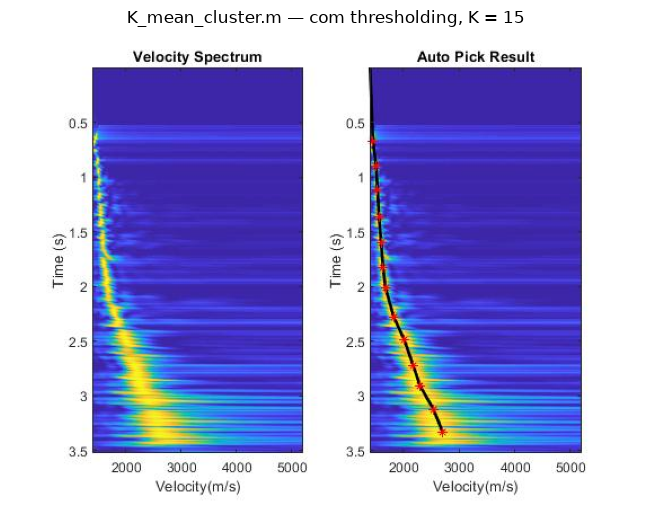

In [17]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

def mostrar(arquivos, titulos, largura=7):
    """Exibe uma ou mais figuras geradas pelos scripts MATLAB lado a lado."""
    fig, axs = plt.subplots(1, len(arquivos), figsize=(largura * len(arquivos), largura * 0.75))
    if len(arquivos) == 1:
        axs = [axs]
    for ax, arq, tit in zip(axs, arquivos, titulos):
        ax.imshow(mpimg.imread(arq))
        ax.set_title(tit)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

mostrar(['imagens/pick_result_default.jpg'], ['K_mean_cluster.m — com thresholding, K = 15'])

Para esta questão foi criado o *script* `K_mean_cluster_no_threshold.m`, idêntico ao `K_mean_cluster.m` exceto pela etapa (2), em que o limiar foi comentado. Assim, todos os $3521 \times 381 = 1\,341\,501$ pontos da grade entram no conjunto de treinamento, e não apenas os de alta *semblance*. O resultado (`pick_result_no_threshold.jpg`) está abaixo, comparado ao resultado original.

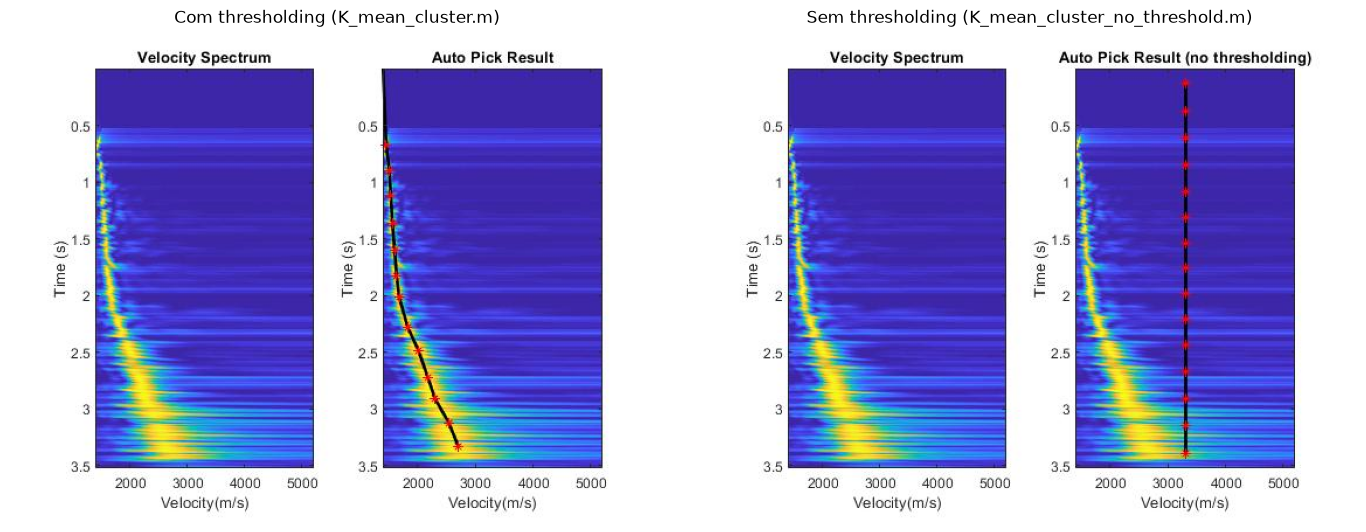

In [18]:
mostrar(['imagens/pick_result_default.jpg', 'imagens/pick_result_no_threshold.jpg'],
        ['Com thresholding (K_mean_cluster.m)', 'Sem thresholding (K_mean_cluster_no_threshold.m)'])

Sem o *thresholding* o K-means falha completamente como método de *picking*. Os 15 centróides convergem para uma linha vertical em, aproximadamente, 3300 m/s, igualmente espaçados no tempo (de 0,1 s a 3,4 s), sem qualquer relação com a faixa de alta *semblance*. Além disso, a execução fica muito mais lenta, pois o laço de atribuição percorre  cerca de 1,3 milhão de pontos a cada iteração.

Isso acontece porque o *thresholding* atua como uma etapa de seleção de dados/extração de *features*: ele descarta o fundo de baixa *semblance* (ruído, regiões sem eventos) e mantém apenas os pontos que pertencem aos máximos do espectro. O limiar usado, `prctile(prctile(vel_spec,90),90)`, é o percentil 90 dos percentis 90 de cada coluna, mantendo apenas uma pequena fração dos pontos mais energéticos. Sem ele, o K-means agrupa a geometria da grade e não a energia do espectro. 

---
**2. How to choose the number of clusters?**

O número de *clusters* $K$ é um hiperparâmetro do K-means: ele não é aprendido pelo algoritmo e precisa ser escolhido. Neste problema, $K$ tem um significado físico direto: é o número de *picks* da função de velocidade. Poucos *clusters* geram uma função grosseira, que não acompanha as mudanças de curvatura do espectro; *clusters* demais começam a subdividir a mesma faixa de energia e podem capturar ruído ou energia de múltiplas.

O critério mais usado para escolher $K$ é o Método do Cotovelo: para cada $K$ calcula-se o *misfit* do agrupamento, isto é, a soma das distâncias quadráticas de cada ponto ao seu centróide (a mesma variável `res` impressa em `K_mean_cluster.m`):

$$J(K) = \sum_{k=1}^{K} \sum_{\mathbf{x}_i \in C_k} \lVert \mathbf{x}_i - \boldsymbol{\mu}_k \rVert^2$$

$J(K)$ sempre diminui quando $K$ aumenta (no limite, $K$ igual ao número de pontos dá $J = 0$), então não faz sentido minimizá-lo. O que se procura é o ponto a partir do qual adicionar *clusters* deixa de reduzir significativamente o *misfit*: o “cotovelo” da curva $J \times K$.

Para isso foi escrito o *script* `K_mean_elbow.m`. Ele aplica o mesmo pré-processamento (filtro mediano e *thresholding*), a mesma inicialização diagonal e as mesmas 15 iterações do programa original, mas de forma vetorizada, para $K = 2, 3, \dots, 30$, e plota o *misfit* final de cada execução.

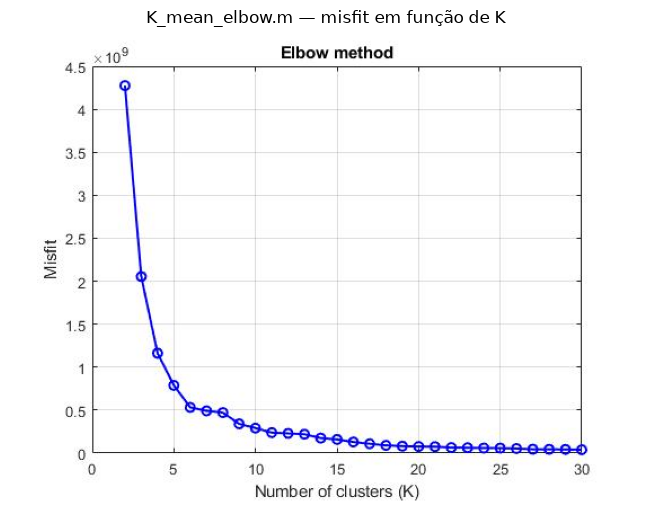

In [19]:
mostrar(['imagens/pick_elbow.jpg'], ['K_mean_elbow.m — misfit em função de K'])

A curva cai rapidamente de $K = 2$ ($\approx 4{,}3 \times 10^9$) até $K = 6$ ($\approx 0{,}5 \times 10^9$) e, a partir daí, decresce lentamente e quase linearmente até zero. O cotovelo está portanto em $K \approx 6$: até esse valor cada *cluster* adicional explica uma parcela grande da dispersão dos pontos; depois dele, os *clusters* extras apenas subdividem regiões já bem representadas.

Para verificar o efeito no *picking*, o `K_mean_cluster.m` foi executado com $K = 6$ (cotovelo), $K = 9$ (um pouco acima do cotovelo) e $K = 15$ (valor original do laboratório), alterando a variável `num_cluster`.

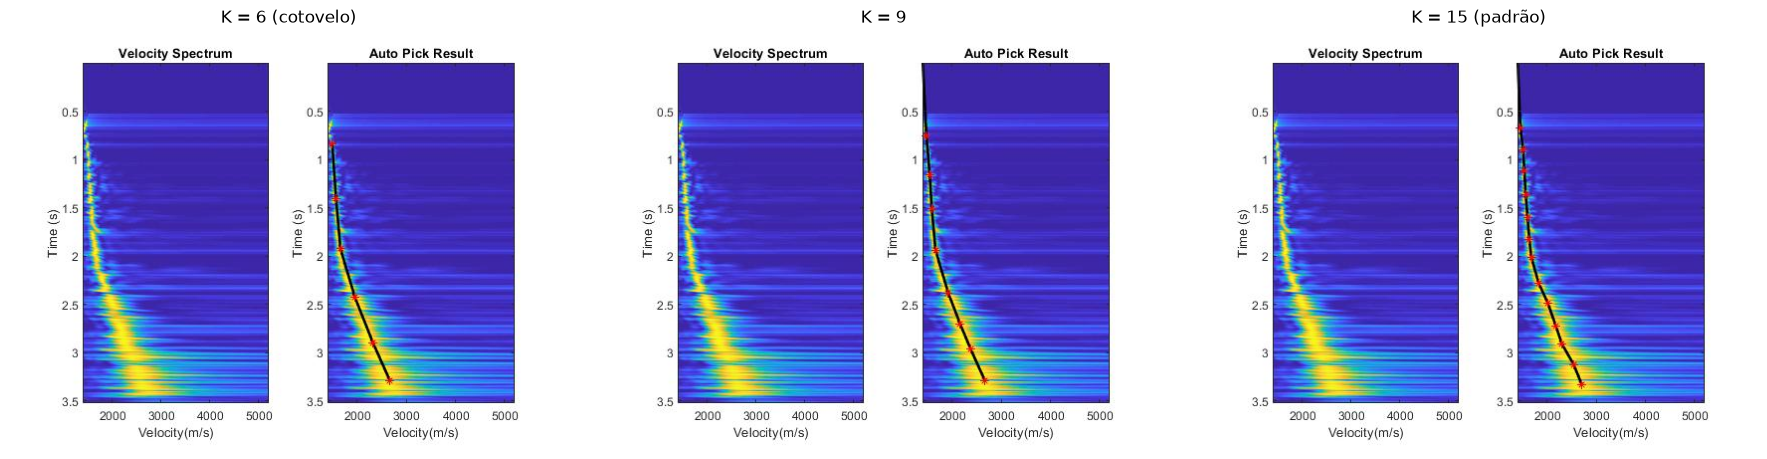

In [20]:
mostrar(['imagens/pick_result_k6.jpg', 'imagens/pick_result_k9.jpg', 'imagens/pick_result_default.jpg'],
        ['K = 6 (cotovelo)', 'K = 9', 'K = 15 (padrão)'], largura=6)

A seguir uma análise dos resultados para cada número de *clusters* definidos acima.

- **$K = 6$:** a curva acompanha corretamente a tendência geral do espectro, com *picks* bem espaçados (~0,5 s) e sem *picks* espúrios. Porém o primeiro *pick* está em ~0,85 s, então a parte rasa (0,6–0,8 s) não é amostrada, e a mudança de curvatura em torno de 2,0–2,5 s é representada de forma grosseira.
- **$K = 9$:** o primeiro *pick* sobe para ~0,65 s e a curva descreve melhor a transição entre o trecho de velocidade quase constante (até ~2 s) e o trecho de aumento rápido (2–3,3 s). É um bom compromisso entre detalhe e robustez.
- **$K = 15$:** fornece a amostragem mais densa e acompanha a faixa de energia com mais detalhe, mas os ganhos em relação a $K = 9$ são pequenos (como prevê a parte plana da curva do cotovelo), e com mais *clusters* aumenta o risco de um centróide cair em energia de ruído ou de múltiplas em espectros menos limpos.